In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/kermany2018")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'kermany2018' dataset.
Path to dataset files: /kaggle/input/kermany2018


In [2]:
import os
import shutil

BASE = "/content/oct"
RAW = os.path.join(BASE, "raw")

os.makedirs(BASE, exist_ok=True)

# Copiez datele
shutil.copytree(path, RAW, dirs_exist_ok=True)

print("RAW structure:")
for root, dirs, files in os.walk(RAW):
    print(root, dirs[:5])
    break


RAW structure:
/content/oct/raw ['OCT2017 ', 'oct2017']


In [12]:
import cv2
import numpy as np

TARGET_SIZE = (224, 224)

def preprocess_oct(image):
    # grayscale
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # resize
    image = cv2.resize(image, TARGET_SIZE)

    # ensure uint8
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8) if image.max() <= 1.0 else image.astype(np.uint8)

    # denoise subtil
    image = cv2.medianBlur(image, 3)

    # CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    image = clahe.apply(image)

    # normalize 0-1
    image = image.astype("float32") / 255.0

    # convert to 3 channels
    return np.stack([image, image, image], axis=-1)


In [36]:
DATASET = "/content/oct/raw/OCT2017 /"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# train
train_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET + "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# vali
val_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET + "val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# test
test_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET + "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

#preprocesare
def prepare_ds(ds):
    return ds.unbatch().map(preprocess_tf, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = prepare_ds(train_ds_raw)
val_ds   = prepare_ds(val_ds_raw)
test_ds  = prepare_ds(test_ds_raw)


Found 83484 files belonging to 4 classes.
Found 32 files belonging to 4 classes.
Found 968 files belonging to 4 classes.


In [27]:
import tensorflow as tf

def preprocess_tf(image, label):
    image = tf.numpy_function(preprocess_oct, [image], Tout=tf.float32)
    image.set_shape([224, 224, 3])
    return image, label


In [28]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

def make_cnn_model():
    base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224,224,3))
    base.trainable = False
    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dense(4, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_model = make_cnn_model()


In [29]:
history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)


Epoch 1/10
   2609/Unknown 339s 126ms/step - accuracy: 0.8096 - loss: 0.5212

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2609/2609 ━━━━━━━━━━━━━━━━━━━━ 343s 128ms/step - accuracy: 0.8096 - loss: 0.5212 - val_accuracy: 0.9062 - val_loss: 0.2210
Epoch 2/10
2609/2609 ━━━━━━━━━━━━━━━━━━━━ 310s 119ms/step - accuracy: 0.8730 - loss: 0.3583 - val_accuracy: 0.9375 - val_loss: 0.1496
Epoch 3/10
2609/2609 ━━━━━━━━━━━━━━━━━━━━ 314s 120ms/step - accuracy: 0.8793 - loss: 0.3386 - val_accuracy: 0.9375 - val_loss: 0.2261
Epoch 4/10
2609/2609 ━━━━━━━━━━━━━━━━━━━━ 316s 121ms/step - accuracy: 0.8819 - loss: 0.3315 - val_accuracy: 0.9375 - val_loss: 0.1303
Epoch 5/10
2609/2609 ━━━━━━━━━━━━━━━━━━━━ 318s 122ms/step - accuracy: 0.8859 - loss: 0.3211 - val_accuracy: 0.9688 - val_loss: 0.1311
Epoch 6/10
2609/2609 ━━━━━━━━━━━━━━━━━━━━ 308s 118ms/step - accuracy: 0.8864 - loss: 0.3194 - val_accuracy: 0.9062 - val_loss: 0.1673
Epoch 7/10
2609/2609 ━━━━━━━━━━━━━━━━━━━━ 382s 146ms/step - accuracy: 0.8886 - loss: 0.3147 - val_accuracy: 0.9375 - val_loss: 0.2020
Epoch 8/10
2609/2609 ━━━━━━━━━━━━━━━━━━━━ 290s 111ms/step - accuracy: 0.8

In [30]:
test_loss, test_acc = cnn_model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


31/31 ━━━━━━━━━━━━━━━━━━━━ 16s 514ms/step - accuracy: 0.9525 - loss: 0.1369
Test Accuracy: 93.39%
Test Loss: 0.1753


31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step
      1/Unknown 0s 159ms/step - accuracy: 0.9688 - loss: 0.0541

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.9525 - loss: 0.1369
Test Accuracy: 93.39%
Test Loss: 0.1753


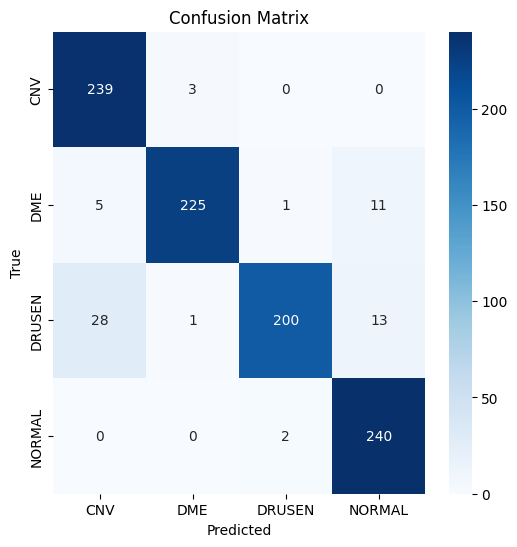

Classification Report:

              precision    recall  f1-score   support

         CNV       0.88      0.99      0.93       242
         DME       0.98      0.93      0.96       242
      DRUSEN       0.99      0.83      0.90       242
      NORMAL       0.91      0.99      0.95       242

    accuracy                           0.93       968
   macro avg       0.94      0.93      0.93       968
weighted avg       0.94      0.93      0.93       968



In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix


class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

# valori reale și predicții
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_pred_probs = cnn_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

#Test loss și accuracy
test_loss, test_acc = cnn_model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

#Matrice
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# tabel
report = classification_report(y_true, y_pred, target_names=class_names)
print("Classification Report:\n")
print(report)


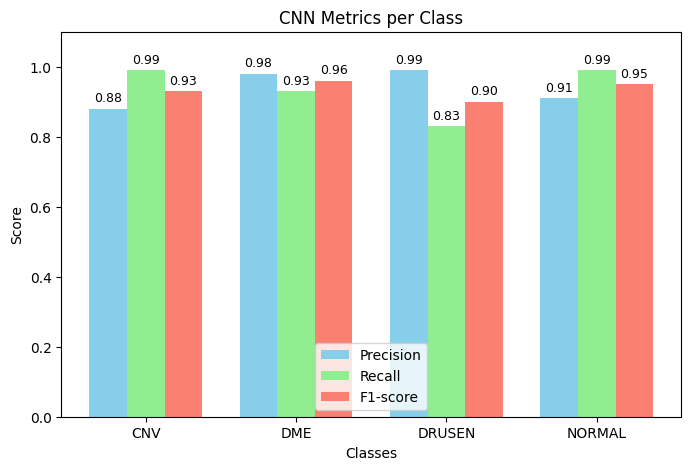

In [39]:
import matplotlib.pyplot as plt
import numpy as np

classes = ["CNV", "DME", "DRUSEN", "NORMAL"]

precision = [0.88, 0.98, 0.99, 0.91]
recall    = [0.99, 0.93, 0.83, 0.99]
f1_score  = [0.93, 0.96, 0.90, 0.95]

x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width, precision, width, label='Precision', color='skyblue')
rects2 = ax.bar(x, recall, width, label='Recall', color='lightgreen')
rects3 = ax.bar(x + width, f1_score, width, label='F1-score', color='salmon')

ax.set_ylabel('Score')
ax.set_xlabel('Classes')
ax.set_title('CNN Metrics per Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0,1.1)
ax.legend()

# Afișez scorurile
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.show()


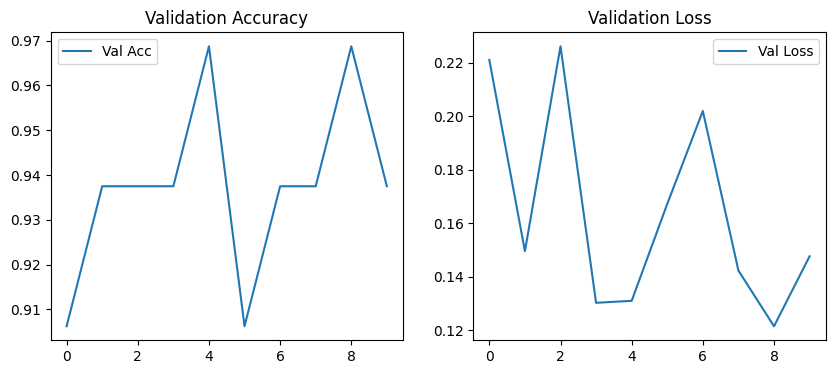

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history["val_accuracy"], label="Val Acc")
plt.title("Validation Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Validation Loss")
plt.legend()

plt.show()


In [40]:
cnn_model.save("oct_cnn_model_MobileNetV2.h5")
